# Лабораторная работа 1

## Загрузка данных

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gzip
import os
import time
import urllib.request

np.random.seed(42)

Скачиваю MNIST в исходном формате (idx-файлы) и читаю их через numpy. Файлы берутся с зеркала Google, т.к. оригинальный сайт Лекуна сейчас часто не отвечает. Если файлы уже скачаны, повторно они не загружаются.

In [2]:
DATA_DIR = 'mnist_data'

FILES = {
    'train_images': 'train-images-idx3-ubyte.gz',
    'train_labels': 'train-labels-idx1-ubyte.gz',
    'test_images':  't10k-images-idx3-ubyte.gz',
    'test_labels':  't10k-labels-idx1-ubyte.gz',
}

URL = 'https://storage.googleapis.com/cvdf-datasets/mnist/'


def download_mnist():
    os.makedirs(DATA_DIR, exist_ok=True)
    for fname in FILES.values():
        path = os.path.join(DATA_DIR, fname)
        if not os.path.exists(path):
            print('скачиваю', URL + fname)
            urllib.request.urlretrieve(URL + fname, path)


def read_images(path):
    with gzip.open(path, 'rb') as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)  # 16 байт - заголовок
    return data.reshape(-1, 28, 28)


def read_labels(path):
    with gzip.open(path, 'rb') as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=8)  # 8 байт - заголовок
    return data


download_mnist()
X_train_raw = read_images(os.path.join(DATA_DIR, FILES['train_images']))
y_train_raw = read_labels(os.path.join(DATA_DIR, FILES['train_labels']))
X_test_raw = read_images(os.path.join(DATA_DIR, FILES['test_images']))
y_test_raw = read_labels(os.path.join(DATA_DIR, FILES['test_labels']))

In [3]:
print('Обучающая выборка:', X_train_raw.shape[0], 'примеров')
print('Тестовая выборка: ', X_test_raw.shape[0], 'примеров')
print('Форма одного изображения:', X_train_raw[0].shape)
print('Форма массива меток:', y_train_raw.shape, ', пример метки:', y_train_raw[0])
print('Тип данных:', X_train_raw.dtype, ', диапазон значений:', X_train_raw.min(), '-', X_train_raw.max())
print('Классы:', np.unique(y_train_raw))

Обучающая выборка: 60000 примеров
Тестовая выборка:  10000 примеров
Форма одного изображения: (28, 28)
Форма массива меток: (60000,) , пример метки: 5
Тип данных: uint8 , диапазон значений: 0 - 255
Классы: [0 1 2 3 4 5 6 7 8 9]


Посмотрим на несколько картинок, чтобы убедиться, что данные загрузились правильно и метки соответствуют изображениям.

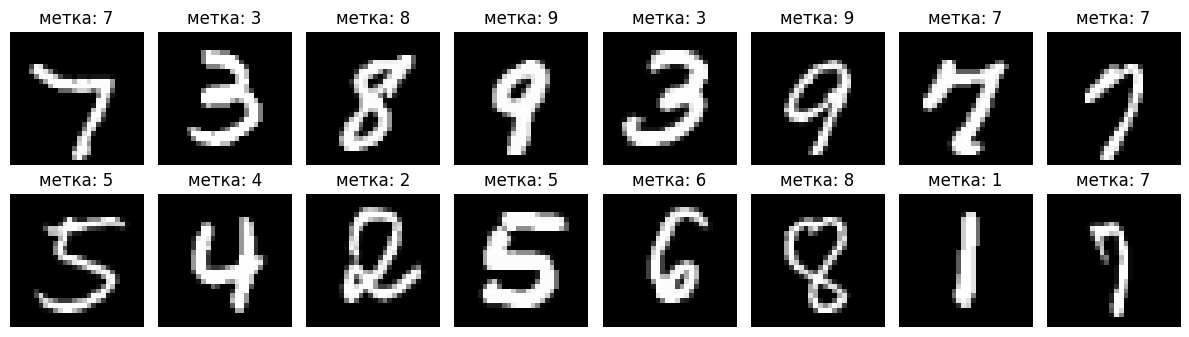

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
idx = np.random.choice(len(X_train_raw), 16, replace=False)
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train_raw[i], cmap='gray')
    ax.set_title(f'метка: {y_train_raw[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Предобработка

- изображения вытягиваем в вектор длины 784 и нормируем в [0, 1] (делим на 255);
- метки переводим в one-hot (вектор из 10 элементов, единица на месте класса).

Использую float32 - так быстрее считается и меньше памяти.

In [5]:
def one_hot(y, num_classes=10):
    res = np.zeros((len(y), num_classes), dtype=np.float32)
    res[np.arange(len(y)), y] = 1.0
    return res


X_train = X_train_raw.reshape(-1, 28 * 28).astype(np.float32) / 255.0
X_test = X_test_raw.reshape(-1, 28 * 28).astype(np.float32) / 255.0
y_train = y_train_raw.astype(np.int64)
y_test = y_test_raw.astype(np.int64)
Y_train = one_hot(y_train)

print('X_train:', X_train.shape, 'Y_train:', Y_train.shape)
print('X_test: ', X_test.shape, 'y_test: ', y_test.shape)
print('метка', y_train[0], '->', Y_train[0])

X_train: (60000, 784) Y_train: (60000, 10)
X_test:  (10000, 784) y_test:  (10000,)
метка 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Реализация нейронной сети

In [6]:
def relu(z):
    return np.maximum(0, z)


def softmax(z):
    # вычитаем максимум по строке, чтобы exp не переполнялся
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def cross_entropy(P, Y):
    # маленькая добавка, чтобы не было log(0)
    return -np.mean(np.sum(Y * np.log(P + 1e-12), axis=1))

In [7]:
class TwoLayerNet:
    def __init__(self, n_input, n_hidden, n_output):
        # инициализация Хе: N(0, 2/n_in)
        self.W1 = (np.random.randn(n_input, n_hidden) * np.sqrt(2.0 / n_input)).astype(np.float32)
        self.b1 = np.zeros(n_hidden, dtype=np.float32)
        self.W2 = (np.random.randn(n_hidden, n_output) * np.sqrt(2.0 / n_hidden)).astype(np.float32)
        self.b2 = np.zeros(n_output, dtype=np.float32)

    def forward(self, X):
        # сохраняем промежуточные значения - они нужны в backward
        self.X = X
        self.Z1 = X @ self.W1 + self.b1
        self.H = relu(self.Z1)
        self.Z2 = self.H @ self.W2 + self.b2
        self.P = softmax(self.Z2)
        return self.P

    def backward(self, Y):
        B = Y.shape[0]
        # выходной слой: dL/dZ2 = (P - Y) / B
        dZ2 = (self.P - Y) / B
        self.dW2 = self.H.T @ dZ2
        self.db2 = dZ2.sum(axis=0)
        # скрытый слой
        dH = dZ2 @ self.W2.T
        dZ1 = dH * (self.Z1 > 0)  # производная ReLU
        self.dW1 = self.X.T @ dZ1
        self.db1 = dZ1.sum(axis=0)

    def step(self, lr):
        self.W1 -= lr * self.dW1
        self.b1 -= lr * self.db1
        self.W2 -= lr * self.dW2
        self.b2 -= lr * self.db2

    def predict(self, X):
        Z1 = X @ self.W1 + self.b1
        Z2 = relu(Z1) @ self.W2 + self.b2
        return np.argmax(Z2, axis=1)  # softmax для argmax не нужен

## Обучение

In [8]:
def accuracy(net, X, y, batch=10000):
    correct = 0
    for i in range(0, len(X), batch):
        correct += np.sum(net.predict(X[i:i + batch]) == y[i:i + batch])
    return correct / len(X)


def train(net, X, Y, y, lr, batch_size, epochs):
    n = X.shape[0]
    history = {'loss': [], 'train_err': []}
    for epoch in range(epochs):
        t0 = time.time()
        perm = np.random.permutation(n)  # перемешиваем каждую эпоху
        epoch_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            Xb, Yb = X[idx], Y[idx]
            P = net.forward(Xb)
            epoch_loss += cross_entropy(P, Yb) * len(idx)
            net.backward(Yb)
            net.step(lr)
        epoch_time = time.time() - t0

        epoch_loss /= n
        train_err = 1 - accuracy(net, X, y)
        history['loss'].append(epoch_loss)
        history['train_err'].append(train_err)
        print(f'Эпоха {epoch + 1:2d}/{epochs}: loss = {epoch_loss:.4f}, '
              f'ошибка на train = {train_err * 100:.2f}% (точность {(1 - train_err) * 100:.2f}%), '
              f'время = {epoch_time:.1f} c')
    return history

Контрольные параметры:

In [9]:
BATCH_SIZE = 32
LEARNING_RATE = 0.1
HIDDEN = 300
EPOCHS = 20

np.random.seed(0)
net = TwoLayerNet(28 * 28, HIDDEN, 10)

t_start = time.time()
history = train(net, X_train, Y_train, y_train, LEARNING_RATE, BATCH_SIZE, EPOCHS)
print(f'\nОбщее время обучения: {time.time() - t_start:.1f} c')

Эпоха  1/20: loss = 0.2894, ошибка на train = 4.35% (точность 95.65%), время = 11.0 c
Эпоха  2/20: loss = 0.1348, ошибка на train = 2.82% (точность 97.18%), время = 11.8 c
Эпоха  3/20: loss = 0.0943, ошибка на train = 1.97% (точность 98.03%), время = 11.3 c
Эпоха  4/20: loss = 0.0731, ошибка на train = 1.43% (точность 98.57%), время = 4.2 c
Эпоха  5/20: loss = 0.0583, ошибка на train = 1.46% (точность 98.54%), время = 2.4 c
Эпоха  6/20: loss = 0.0486, ошибка на train = 1.02% (точность 98.98%), время = 2.1 c
Эпоха  7/20: loss = 0.0401, ошибка на train = 0.81% (точность 99.19%), время = 2.8 c
Эпоха  8/20: loss = 0.0340, ошибка на train = 0.64% (точность 99.36%), время = 5.0 c
Эпоха  9/20: loss = 0.0281, ошибка на train = 0.45% (точность 99.55%), время = 2.1 c
Эпоха 10/20: loss = 0.0240, ошибка на train = 0.33% (точность 99.67%), время = 2.3 c
Эпоха 11/20: loss = 0.0201, ошибка на train = 0.26% (точность 99.74%), время = 2.0 c
Эпоха 12/20: loss = 0.0174, ошибка на train = 0.23% (точность 

## Результаты на тестовой выборке

In [10]:
test_acc = accuracy(net, X_test, y_test)
test_loss = cross_entropy(net.forward(X_test), one_hot(y_test))
print(f'Тестовая выборка: loss = {test_loss:.4f}')
print(f'Ошибка классификации на test: {(1 - test_acc) * 100:.2f}%')
print(f'Точность на test: {test_acc * 100:.2f}%')

Тестовая выборка: loss = 0.0639
Ошибка классификации на test: 1.81%
Точность на test: 98.19%


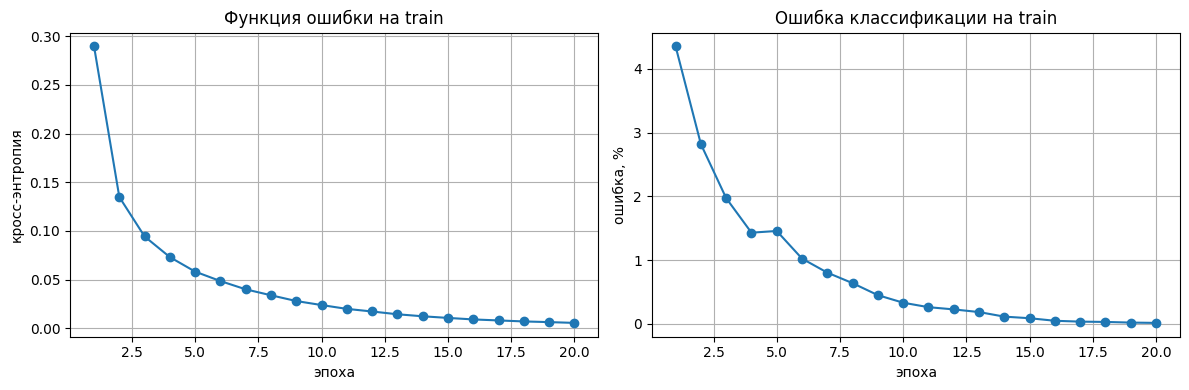

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ep = np.arange(1, EPOCHS + 1)
ax[0].plot(ep, history['loss'], marker='o')
ax[0].set_xlabel('эпоха')
ax[0].set_ylabel('кросс-энтропия')
ax[0].set_title('Функция ошибки на train')
ax[0].grid(True)

ax[1].plot(ep, np.array(history['train_err']) * 100, marker='o')
ax[1].set_xlabel('эпоха')
ax[1].set_ylabel('ошибка, %')
ax[1].set_title('Ошибка классификации на train')
ax[1].grid(True)
plt.tight_layout()
plt.show()

Посмотрим на примеры, где сеть ошиблась на тестовой выборке:

Всего ошибок: 181 из 10000


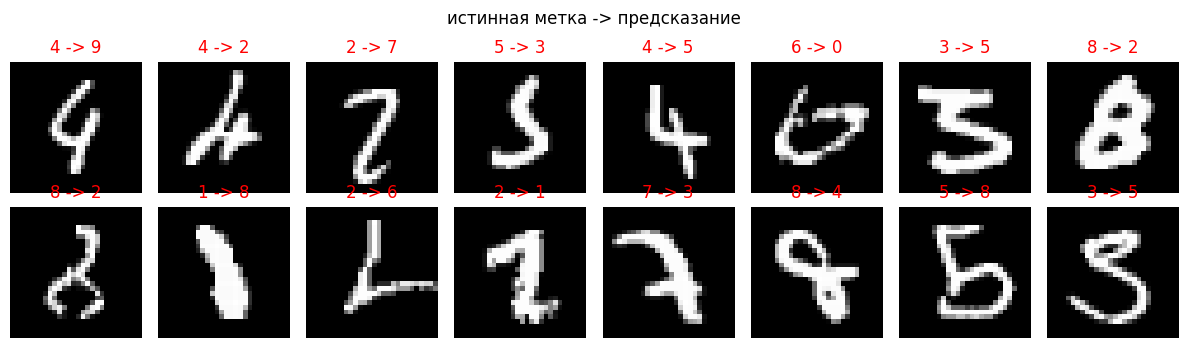

In [12]:
pred = net.predict(X_test)
wrong = np.where(pred != y_test)[0]
print('Всего ошибок:', len(wrong), 'из', len(y_test))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(X_test_raw[i], cmap='gray')
    ax.set_title(f'{y_test[i]} -> {pred[i]}', color='red')
    ax.axis('off')
plt.suptitle('истинная метка -> предсказание')
plt.tight_layout()
plt.show()

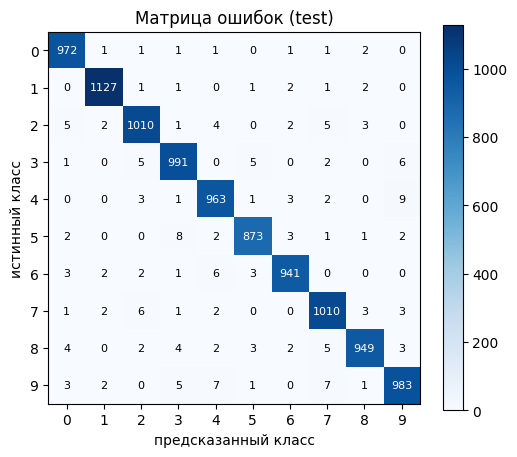

In [13]:
# матрица ошибок
conf = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test, pred):
    conf[t, p] += 1

plt.figure(figsize=(6, 5))
plt.imshow(conf, cmap='Blues')
plt.colorbar()
for i in range(10):
    for j in range(10):
        plt.text(j, i, conf[i, j], ha='center', va='center',
                 color='white' if conf[i, j] > conf.max() / 2 else 'black', fontsize=8)
plt.xlabel('предсказанный класс')
plt.ylabel('истинный класс')
plt.xticks(range(10))
plt.yticks(range(10))
plt.title('Матрица ошибок (test)')
plt.show()